# 02 · UHI index model (final submission)

This notebook predicts the **Urban Heat Island (UHI) index** at street-level points in the Bronx and Manhattan with XGBoost. The features come from satellite imagery, building footprints and weather stations. It walks through the pipeline step by step. The logic lives in the `uhi` package (`src/uhi`), and `python -m uhi.pipeline` runs the same steps end to end.

**Pipeline**
1. Read the ground-truth points and the satellite GeoTIFFs produced by `01_satellite_data_extraction.ipynb` (one row per 10 m pixel).
2. Add the weather-station readings (Bronx / Manhattan) averaged over 15:00–16:00 on the survey day.
3. Engineer spectral indices, single-day vs. median change features and weather interaction terms.
4. Keep only the pixels within 500 m of a training or submission point.
5. Add building-footprint features: distance to the nearest building and building statistics within 500 m.
6. Add 100 m focal (neighbourhood mean) versions of the key features.
7. Give every training / submission point the features of its nearest pixel.
8. Train XGBoost on the selected features, evaluate it and predict the submission points.

**Inputs:** the challenge files in `data/raw/` (see `data/README.md`) and the GeoTIFFs in `data/processed/`.
**Output:** `outputs/submission_4.3.csv`.

> **About the outputs.** Every output below comes from one top-to-bottom run of this notebook on the challenge data, using the nearest-neighbour GeoTIFFs written by `01_satellite_data_extraction.ipynb`. During the competition the notebook was run interactively with bilinearly resampled Landsat and MODIS layers. Those results (hold-out R² 0.968 with the same 52 features) are kept in the log cells of sections 9 and 10.

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import gc

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from uhi import config, modeling, raster
from uhi.features import buildings, spatial, spectral, weather

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 50)

# Set to True to plot every band of the GeoTIFFs (slow and memory hungry)
SHOW_BAND_PLOTS = False

## 1. Ground truth

In [2]:
# Training data: UHI index measured on 24 July 2021 between 15:00 and 16:00
ground_df = pd.read_csv(config.RAW_DIR / config.TRAINING_FILE)
# Points to predict
test_df = pd.read_csv(config.RAW_DIR / config.SUBMISSION_TEMPLATE_FILE)

print(f"{len(ground_df):,} training points, {len(test_df):,} points to predict")
ground_df.head()

11,229 training points, 1,040 points to predict


,Longitude,Latitude,datetime,UHI Index
0,-73.909167,40.813107,24-07-2021 15:53,1.030289
1,-73.909187,40.813045,24-07-2021 15:53,1.030289
2,-73.909215,40.812978,24-07-2021 15:53,1.023798
3,-73.909242,40.812908,24-07-2021 15:53,1.023798
4,-73.909257,40.812845,24-07-2021 15:53,1.021634


In [3]:
ground_df["UHI Index"].describe()

count    11229.000000
mean         1.000001
std          0.016238
min          0.956122
25%          0.988577
50%          1.000237
75%          1.011176
max          1.046036
Name: UHI Index, dtype: float64

## 2. Satellite features
All six GeoTIFFs share one grid of 1448 × 1671 pixels of 10 m. `raster.pixel_table` flattens each file (row-major order) and puts them side by side: Sentinel-2 and Landsat bands with a `_single` (single date) and a `_median` (summer median) version, and the MODIS composites with a `_mean` suffix.

In [4]:
pixels = raster.pixel_table(config.PROCESSED_DIR, method="nearest")
print(pixels.shape)
pixels.head()

(2419608, 67)


,Longitude,Latitude,B01_single,B02_single,B03_single,B04_single,B05_single,B06_single,B07_single,B08_single,B8A_single,B09_single,B11_single,B12_single,AOT_single,WVP_single,visual_single,SCL_single,B01_median,B02_median,B03_median,B04_median,B05_median,B06_median,B07_median,B08_median,B8A_median,B09_median,B11_median,B12_median,AOT_median,WVP_median,visual_median,SCL_median,red_single,green_single,blue_single,nir08_single,swir16_single,swir22_single,coastal_single,emis_single,emsd_single,trad_single,urad_single,atran_single,cdist_single,lwir11_single,red_median,green_median,blue_median,nir08_median,swir16_median,swir22_median,coastal_median,emis_median,emsd_median,trad_median,urad_median,atran_median,cdist_median,lwir11_median,LST_mean,Emis_31_mean,Emis_32_mean,NDVI_mean,EVI_mean
0,-74.009955,40.879955,643.0,639.0,728.0,839.0,1023.0,2034.0,2064.0,1440.0,2438.0,2384.0,1578.0,1083.0,163.0,1795.0,86.0,4.0,676.5,703.0,848.0,850.0,1060.0,2084.5,2321.0,2020.0,2613.0,2729.5,1778.0,1198.0,150.5,2836.5,87.0,4.0,0.066393,0.068317,0.045465,0.227762,0.149855,0.100108,0.042110,0.9592,0.0098,9.947,1.038,0.8501,2.32,34.329915,0.070999,0.074794,0.052477,0.246641,0.164430,0.107285,0.045327,0.9615,0.0098,9.9470,3.257,0.6133,2.305,34.066728,32.09,0.48,0.486,0.6164,0.4305
1,-74.009865,40.879955,643.0,639.0,728.0,839.0,1023.0,2034.0,2064.0,1440.0,2438.0,2384.0,1578.0,1083.0,163.0,1795.0,86.0,4.0,676.5,703.0,848.0,850.0,1060.0,2084.5,2321.0,2020.0,2613.0,2729.5,1778.0,1198.0,150.5,2836.5,87.0,4.0,0.066393,0.068317,0.045465,0.227762,0.149855,0.100108,0.042110,0.9592,0.0098,9.947,1.038,0.8501,2.32,34.329915,0.070999,0.074794,0.052477,0.246641,0.164430,0.107285,0.045327,0.9615,0.0098,9.9470,3.257,0.6133,2.305,34.066728,32.09,0.48,0.486,0.6164,0.4305
2,-74.009776,40.879955,882.0,395.0,579.0,415.0,889.0,1850.0,2216.0,2354.0,2133.0,2438.0,1554.0,1029.0,163.0,1839.0,43.0,4.0,880.0,644.5,810.5,793.0,1142.5,1967.5,2330.5,2360.0,2279.5,2552.5,1817.0,1371.5,150.5,2927.5,81.0,4.0,0.098457,0.092077,0.074560,0.208018,0.182360,0.143145,0.066585,0.9758,0.0071,9.925,1.038,0.8501,2.35,34.329915,0.102857,0.100644,0.076623,0.220681,0.195505,0.145070,0.067273,0.9665,0.0071,9.9245,3.257,0.6133,2.335,34.066728,32.09,0.48,0.486,0.6164,0.4305
3,-74.009686,40.879955,882.0,562.0,775.0,688.0,889.0,1850.0,2216.0,2270.0,2133.0,2438.0,1554.0,1029.0,163.0,1839.0,70.0,4.0,880.0,751.0,917.5,926.0,1142.5,1967.5,2330.5,2490.0,2279.5,2552.5,1817.0,1371.5,150.5,2927.5,94.5,4.0,0.098457,0.092077,0.074560,0.208018,0.182360,0.143145,0.066585,0.9758,0.0071,9.925,1.038,0.8501,2.35,34.329915,0.102857,0.100644,0.076623,0.220681,0.195505,0.145070,0.067273,0.9665,0.0071,9.9245,3.257,0.6133,2.335,34.066728,32.09,0.48,0.486,0.6164,0.4305
4,-74.009596,40.879955,882.0,919.0,1036.0,1108.0,1201.0,1566.0,1757.0,1584.0,1908.0,2438.0,1742.0,1353.0,163.0,1839.0,113.0,5.0,880.0,966.0,1016.0,1041.5,1477.5,1817.0,1811.5,1567.0,1915.0,2552.5,2094.0,1602.5,150.5,2836.5,106.5,5.0,0.098457,0.092077,0.074560,0.208018,0.182360,0.143145,0.066585,0.9758,0.0071,9.925,1.038,0.8501,2.35,34.329915,0.102857,0.100644,0.076623,0.220681,0.195505,0.145070,0.067273,0.9665,0.0071,9.9245,3.257,0.6133,2.335,34.066728,32.09,0.48,0.486,0.6164,0.4305


In [5]:
# Optional: plot every band of every GeoTIFF
if SHOW_BAND_PLOTS:
    names = config.geotiff_names("nearest")
    raster.plot_bands(config.PROCESSED_DIR / names["s2_single"], config.S2_BANDS)
    raster.plot_bands(config.PROCESSED_DIR / names["s2_median"], config.S2_BANDS)
    raster.plot_bands(config.PROCESSED_DIR / names["landsat_single"], config.LANDSAT_BANDS)
    raster.plot_bands(config.PROCESSED_DIR / names["landsat_median"], config.LANDSAT_BANDS)
    raster.plot_bands(config.PROCESSED_DIR / names["modis_lst"], config.MODIS_LST_BANDS, cmap="magma")
    raster.plot_bands(config.PROCESSED_DIR / names["modis_vi"], config.MODIS_VI_BANDS)

## 3. Weather data
The NY Mesonet provides one weather station in the Bronx and one in Manhattan. Their readings are averaged over the survey hour (15:00–16:00). Every pixel takes the values of its borough's station; the boroughs are split by a straight line through (-73.92, 40.78) and (-73.94, 40.825).

In [6]:
stations = pd.ExcelFile(config.RAW_DIR / config.WEATHER_FILE)
bronx = weather.survey_hour_means(weather.read_station(stations, "Bronx"))
manhattan = weather.survey_hour_means(weather.read_station(stations, "Manhattan"))
pd.DataFrame({"Bronx": bronx, "Manhattan": manhattan})

,Bronx,Manhattan
Air Temp at Surface [degC],27.492308,26.753846
Relative Humidity [percent],44.615385,48.353846
Avg Wind Speed [m/s],3.100000,2.946154
Wind Direction [degrees],135.076923,171.076923
Solar Flux [W/m^2],445.692308,441.000000


In [7]:
weather.add_station_weather(pixels, bronx, manhattan)
pixels["is_bronx"].value_counts().rename(index={0: "Manhattan", 1: "Bronx"})

is_bronx
Bronx        1218753
Manhattan    1200855
Name: count, dtype: int64

## 4. Feature engineering
Spectral indices (NDVI, NDBI, NDWI, NDTI, EVI, BSR, broadband albedo), single-day minus / over median change features for all 30 bands, and weather interaction terms. Rows with missing or infinite values are dropped.

In [8]:
pixels.dropna(inplace=True)
spectral.add_spectral_indices(pixels)
spectral.add_temporal_change(pixels)
weather.add_interactions(pixels)
pixels = pixels[np.isfinite(pixels).all(axis=1)]
gc.collect()
print(pixels.shape)

(2415975, 165)


## 5. Keep the pixels near the target points
Later steps only need the pixels close to a training or submission point. A bounding-box pre-filter is followed by a chunked spatial join against 500-unit buffers in EPSG:3857 (about 380 m on the ground at this latitude). Only the geometry goes through the join: neighbouring points have heavily overlapping buffers, and joining every column would need more than 10 GB per chunk.

In [9]:
pixel_gdf = spatial.points_to_gdf(pixels)  # shares the columns of `pixels`, no copy
ground_gdf = spatial.points_to_gdf(ground_df)
test_gdf = spatial.points_to_gdf(test_df)
del pixels

near, info = spatial.pixels_near_points(pixel_gdf, [ground_gdf, test_gdf], radius=config.PIXEL_FILTER_RADIUS)
del pixel_gdf
gc.collect()
print(f"{info['in_bounding_box']:,} of {info['pixels']:,} pixels inside the bounding box of the buffers; "
      f"{info['kept']:,} within {config.PIXEL_FILTER_RADIUS} units of a point")

1,650,512 of 2,415,975 pixels inside the bounding box of the buffers; 620,865 within 500 units of a point


## 6. Building footprint features
The building footprints give two kinds of features for every pixel:

- **Distance to the nearest building:** shorter distances usually mean denser urban areas.
- **Building statistics within 500 units:** the number, footprint area, perimeter and compactness of the surrounding buildings, plus density and coverage ratio.

9,436 building footprints


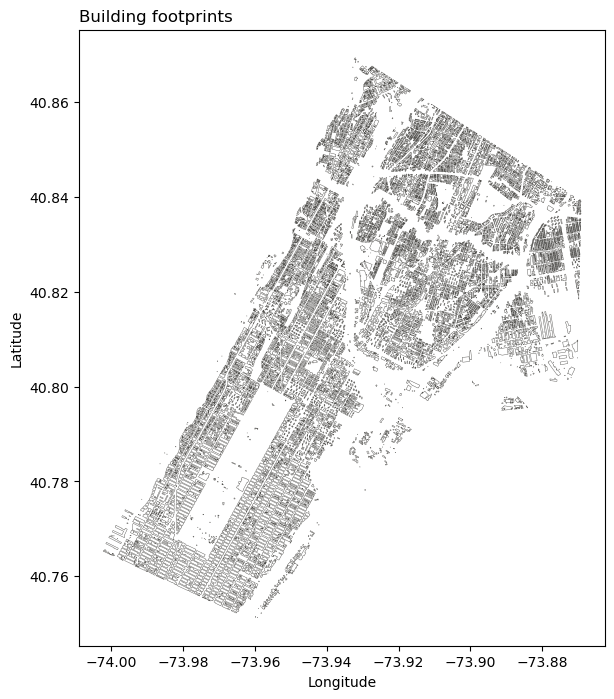

In [10]:
footprints = buildings.read_footprints(config.RAW_DIR / config.BUILDINGS_FILE)
print(f"{len(footprints):,} building footprints")

ax = footprints.plot(edgecolor="#52514e", facecolor="none", linewidth=0.3, figsize=(8, 8))
ax.set_title("Building footprints", loc="left", fontsize=12)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()

In [11]:
footprints = footprints.to_crs(epsg=3857)
near = buildings.nearest_building_distance(near, footprints)

# Per-building shape metrics (only area, perimeter and compactness feed the statistics below)
shapes = buildings.shape_metrics(footprints)
shapes.drop(columns="geometry").describe().T

,count,mean,std,min,25%,50%,75%,max
building_area,9436.0,3490.135498,5522.629118,2.614958,472.543587,1438.385021,3807.986894,124757.432766
perimeter,9436.0,267.827037,246.044960,8.406353,93.253059,189.904765,353.502284,6387.186790
compactness,9436.0,0.538413,0.184135,0.038429,0.391568,0.569874,0.702219,0.916933
solidity,9436.0,0.909522,0.114467,0.328964,0.845993,0.961825,1.000000,1.000000
long_width_ratio,9436.0,2.154565,1.179822,1.000101,1.382572,1.859081,2.615752,31.101635
rotation_angle,9436.0,102.530939,51.918381,0.000000,64.119925,96.475742,153.683558,180.000000


In [12]:
%%time
# Building statistics around every pixel (the slowest step: about 15 minutes)
near = buildings.buffer_stats(near, shapes, radius=config.BUILDING_RADIUS)
near[buildings.BUFFER_STATS].describe().T

CPU times: total: 27min 43s
Wall time: 12min 48s


,count,mean,std,min,25%,50%,75%,max
building_count,621141.0,65.639871,39.108386,0.0,37.000000,57.000000,88.000000,234.000000
total_building_area,621141.0,292742.358026,145586.792827,0.0,188616.377715,280995.742381,371927.362452,778263.309240
avg_building_area,621141.0,5736.303278,3824.941085,0.0,2867.281971,4601.092388,7302.704716,23360.957819
total_building_perimeter,621141.0,20707.795099,8874.203454,0.0,14138.638663,22063.545773,27862.830954,45509.943214
avg_building_perimeter,621141.0,358.304370,135.194954,0.0,250.618988,337.179932,450.091300,1323.415842
std_building_area,621141.0,6035.378649,3864.877582,0.0,3585.194255,5085.825761,7283.621828,43478.609693
avg_building_compactness,621141.0,0.508211,0.067911,0.0,0.459769,0.506319,0.554189,0.785022
total_building_compactness,621141.0,33.572344,21.806329,0.0,18.523079,27.432878,43.833258,143.477972
building_density,621141.0,0.000084,0.000050,0.0,0.000047,0.000073,0.000112,0.000298
building_coverage_ratio,621141.0,0.373331,0.185665,0.0,0.240540,0.358350,0.474314,0.992509


## 7. Focal (100 unit neighbourhood) features
For every pixel, the mean of 64 features over all pixels within 100 units is added as `buffered_<feature>`. Pixels are processed in chunks of 100,000 rows, and neighbours are searched within the same chunk.

In [13]:
%%time
near = spatial.focal_means(near, config.FOCAL_FEATURES, radius=config.FOCAL_RADIUS,
                           chunk_size=config.FOCAL_CHUNK_SIZE)
print(near.shape)

(621141, 242)
CPU times: total: 2min 45s
Wall time: 2min 46s


## 8. Attach pixel features to the training and submission points
Every point takes the features of its nearest pixel (`sjoin_nearest`). The distance to that pixel is kept as `nearest_distance`, and the few remaining missing values are set to 0.

In [14]:
ground_mapped = spatial.map_nearest_pixel(ground_gdf[["Longitude", "Latitude", config.TARGET, "geometry"]], near)
test_mapped = spatial.map_nearest_pixel(test_gdf, near)
print("Missing values set to 0:", int(ground_mapped.isna().sum().sum()), "(training),",
      int(test_mapped.drop(columns=config.TARGET).isna().sum().sum()), "(submission)")
ground_mapped = ground_mapped.fillna(0)
test_mapped = test_mapped.fillna(0)
del near
gc.collect()

ground_mapped["nearest_distance"].describe()

Missing values set to 0: 0 (training), 0 (submission)


count    11229.000000
mean         4.464949
std          1.722237
min          0.035699
25%          3.239732
50%          4.585957
75%          5.803595
max         11.151742
Name: nearest_distance, dtype: float64

## 9. Training table and feature selection
Duplicate feature rows and rows with missing / infinite values are removed, and the join columns and the borough flag are dropped.

In [15]:
table = modeling.prepare_training_table(ground_mapped)
X = modeling.numeric_features(table)
print(f"{len(table):,} training rows, {X.shape[1]} candidate features")

11,229 training rows, 239 candidate features


### Recursive feature elimination (RFECV)
RFECV runs 5-fold CV with R² scoring on an 80/20 train/test split, removing one feature per step. With the tuned model, it selected the **52 features in `config.SELECTED_FEATURES`**, which the final model uses. Each search takes from 15 minutes (default parameters) to several hours (tuned model), so both are kept as raw cells, and their outputs are in the logs below.

#### RFECV with default parameters on the current inputs

Output of the default-parameter run above, from a run of this pipeline on the same data (September 2026).

```text
Optimal number of features:  59
Test R² score:  0.9546936214915763
Selected features:  ['B09_median', 'emis_single', 'emsd_single', 'trad_single', 'cdist_single', 'lwir11_single', 'emis_median', 'trad_median', 'urad_median', 'atran_median', 'cdist_median', 'lwir11_median', 'LST_mean', 'Emis_31_mean', 'NDVI_mean', 'EVI_mean', 'Air Temp at Surface [degC]', 'B01_diff', 'emis_diff', 'emis_ratio', 'urad_ratio', 'atran_diff', 'cdist_diff', 'cdist_ratio', 'lwir11_diff', 'lwir11_ratio', 'total_building_area', 'std_building_area', 'avg_building_compactness', 'total_building_compactness', 'area_to_perimeter_ratio', 'buffered_B01_single', 'buffered_B09_single', 'buffered_B12_single', 'buffered_WVP_single', 'buffered_SCL_single', 'buffered_emis_single', 'buffered_trad_single', 'buffered_urad_single', 'buffered_atran_single', 'buffered_cdist_single', 'buffered_lwir11_single', 'buffered_NDVI_single_lst', 'buffered_NDBIa_single', 'buffered_NDWI_single', 'buffered_NDTI_single', 'buffered_EVI_single', 'buffered_Green_Heat_Reflection', 'buffered_Urban_Water_Buffer', 'buffered_nearest_building_distance', 'buffered_building_density', 'buffered_total_building_area', 'buffered_avg_building_area', 'buffered_total_building_perimeter', 'buffered_avg_building_perimeter', 'buffered_std_building_area', 'buffered_avg_building_compactness', 'buffered_total_building_compactness', 'buffered_area_to_perimeter_ratio']
```

#### Log of the competition-time RFECV runs

Outputs of the RFECV runs made during the competition, kept for reference. At that time the Landsat and MODIS layers were resampled bilinearly, so the numbers differ slightly from a run on the current inputs.

**Tuned model: the 52 features used by the final model**

```text
Optimal number of features:  52
Test R² score:  0.9685968734387487
Selected features:  ['B01_single', 'B09_single', 'urad_single', 'atran_single', 'cdist_single', 'urad_median', 'atran_median', 'cdist_median', 'lwir11_median', 'LST_mean', 'Emis_31_mean', 'Emis_32_mean', 'NDVI_mean', 'EVI_mean', 'B01_diff', 'B01_ratio', 'B09_diff', 'B09_ratio', 'urad_diff', 'urad_ratio', 'atran_diff', 'atran_ratio', 'cdist_diff', 'cdist_ratio', 'building_count', 'total_building_area', 'avg_building_area', 'total_building_perimeter', 'avg_building_perimeter', 'std_building_area', 'avg_building_compactness', 'total_building_compactness', 'area_to_perimeter_ratio', 'buffered_urad_single', 'buffered_atran_single', 'buffered_cdist_single', 'buffered_lwir11_single', 'buffered_NDVI_single_lst', 'buffered_NDBIa_single', 'buffered_NDWI_single', 'buffered_NDTI_single', 'buffered_building_density', 'buffered_building_count', 'buffered_total_building_area', 'buffered_avg_building_area', 'buffered_total_building_perimeter', 'buffered_avg_building_perimeter', 'buffered_std_building_area', 'buffered_avg_building_compactness', 'buffered_total_building_compactness', 'buffered_building_coverage_ratio', 'buffered_area_to_perimeter_ratio']
```

**Default parameters**

```text
Optimal number of features:  52
Test R² score:  0.9552669878210238
Selected features:  ['emis_median', 'urad_median', 'atran_median', 'cdist_median', 'lwir11_median', 'LST_mean', 'Emis_31_mean', 'Emis_32_mean', 'NDVI_mean', 'EVI_mean', 'B01_diff', 'B09_diff', 'emis_diff', 'emis_ratio', 'urad_diff', 'urad_ratio', 'atran_diff', 'atran_ratio', 'cdist_diff', 'cdist_ratio', 'lwir11_ratio', 'building_count', 'total_building_area', 'avg_building_area', 'total_building_perimeter', 'avg_building_perimeter', 'std_building_area', 'avg_building_compactness', 'total_building_compactness', 'area_to_perimeter_ratio', 'buffered_B01_single', 'buffered_WVP_single', 'buffered_nir08_single', 'buffered_urad_single', 'buffered_cdist_single', 'buffered_lwir11_single', 'buffered_NDVI_single_lst', 'buffered_NDBIa_single', 'buffered_NDWI_single', 'buffered_BSR_single', 'buffered_Green_Heat_Reflection', 'buffered_Urban_Water_Buffer', 'buffered_nearest_building_distance', 'buffered_building_density', 'buffered_building_count', 'buffered_total_building_area', 'buffered_avg_building_area', 'buffered_avg_building_perimeter', 'buffered_std_building_area', 'buffered_avg_building_compactness', 'buffered_total_building_compactness', 'buffered_area_to_perimeter_ratio']
```

**Earlier run**

```text
Optimal number of features:  79
Test R² score:  0.9671352018922474
Selected features:  ['B01_single', 'B09_single', 'B01_median', 'B09_median', 'emis_single', 'emsd_single', 'trad_single', 'urad_single', 'atran_single', 'cdist_single', 'lwir11_single', 'emis_median', 'emsd_median', 'trad_median', 'urad_median', 'atran_median', 'cdist_median', 'lwir11_median', 'Air Temp at Surface [degC]', 'Relative Humidity [percent]', 'B01_diff', 'B01_ratio', 'B09_diff', 'B09_ratio', 'urad_diff', 'urad_ratio', 'atran_diff', 'atran_ratio', 'cdist_diff', 'cdist_ratio', 'building_density', 'building_count', 'total_building_area', 'avg_building_area', 'total_building_perimeter', 'avg_building_perimeter', 'std_building_area', 'avg_building_compactness', 'total_building_compactness', 'building_coverage_ratio', 'area_to_perimeter_ratio', 'buffered_B01_single', 'buffered_B05_single', 'buffered_B09_single', 'buffered_B11_single', 'buffered_B12_single', 'buffered_WVP_single', 'buffered_SCL_single', 'buffered_nir08_single', 'buffered_swir16_single', 'buffered_emis_single', 'buffered_emsd_single', 'buffered_trad_single', 'buffered_urad_single', 'buffered_atran_single', 'buffered_cdist_single', 'buffered_lwir11_single', 'buffered_NDVI_single', 'buffered_NDVI_single_lst', 'buffered_NDBI_single', 'buffered_NDBIa_single', 'buffered_NDWI_single', 'buffered_NDTI_single', 'buffered_Albedo_single', 'buffered_EVI_single', 'buffered_BSR_single', 'buffered_Green_Heat_Reflection', 'buffered_nearest_building_distance', 'buffered_building_density', 'buffered_building_count', 'buffered_total_building_area', 'buffered_avg_building_area', 'buffered_total_building_perimeter', 'buffered_avg_building_perimeter', 'buffered_std_building_area', 'buffered_avg_building_compactness', 'buffered_total_building_compactness', 'buffered_building_coverage_ratio', 'buffered_area_to_perimeter_ratio']
```

**Earlier run, followed by a large grid search**

```text
Optimal number of features:  50
Selected features:  ['atran_single', 'urad_median', 'atran_median', 'cdist_median', 'B09_diff', 'B09_ratio', 'urad_diff', 'urad_ratio', 'atran_diff', 'atran_ratio', 'cdist_diff', 'cdist_ratio', 'building_count', 'total_building_area', 'avg_building_area', 'total_building_perimeter', 'avg_building_perimeter', 'std_building_area', 'avg_building_compactness', 'total_building_compactness', 'area_to_perimeter_ratio', 'buffered_B09_single', 'buffered_B12_single', 'buffered_WVP_single', 'buffered_SCL_single', 'buffered_nir08_single', 'buffered_swir16_single', 'buffered_emis_single', 'buffered_urad_single', 'buffered_atran_single', 'buffered_cdist_single', 'buffered_lwir11_single', 'buffered_NDVI_single', 'buffered_NDVI_single_lst', 'buffered_NDWI_single', 'buffered_NDTI_single', 'buffered_Albedo_single', 'buffered_EVI_single', 'buffered_BSR_single', 'buffered_Green_Heat_Reflection', 'buffered_Urban_Water_Buffer', 'buffered_nearest_building_distance', 'buffered_building_density', 'buffered_total_building_area', 'buffered_avg_building_area', 'buffered_avg_building_perimeter', 'buffered_std_building_area', 'buffered_avg_building_compactness', 'buffered_total_building_compactness', 'buffered_area_to_perimeter_ratio']
Fitting 5 folds for each of 327680 candidates, totalling 1638400 fits
```

**Earlier run (settings noted as "building buffer 100, building grid map 500, buffer 100")**

```text
Optimal number of features:  59
Test R² score:  0.9656536678856374
Selected features:  ['emsd_single', 'atran_single', 'cdist_single', 'lwir11_single', 'emis_median', 'urad_median', 'atran_median', 'cdist_median', 'lwir11_median', 'Air Temp at Surface [degC]', 'B01_diff', 'B01_ratio', 'B09_diff', 'B09_ratio', 'urad_diff', 'urad_ratio', 'atran_diff', 'atran_ratio', 'cdist_diff', 'cdist_ratio', 'building_count', 'total_building_area', 'avg_building_area', 'total_building_perimeter', 'avg_building_perimeter', 'std_building_area', 'avg_building_compactness', 'total_building_compactness', 'building_coverage_ratio', 'area_to_perimeter_ratio', 'buffered_B01_single', 'buffered_B09_single', 'buffered_B11_single', 'buffered_WVP_single', 'buffered_emis_single', 'buffered_emsd_single', 'buffered_trad_single', 'buffered_urad_single', 'buffered_atran_single', 'buffered_cdist_single', 'buffered_lwir11_single', 'buffered_NDVI_single', 'buffered_NDVI_single_lst', 'buffered_NDBIa_single', 'buffered_NDWI_single', 'buffered_BSR_single', 'buffered_Green_Heat_Reflection', 'buffered_nearest_building_distance', 'buffered_building_density', 'buffered_building_count', 'buffered_total_building_area', 'buffered_avg_building_area', 'buffered_total_building_perimeter', 'buffered_avg_building_perimeter', 'buffered_std_building_area', 'buffered_avg_building_compactness', 'buffered_total_building_compactness', 'buffered_building_coverage_ratio', 'buffered_area_to_perimeter_ratio']
```

## 10. Model training
XGBoost with the hyper-parameters in `config.XGB_PARAMS` (from the grid search below) on the 52 selected features. The model is evaluated with 5-fold cross-validation on the 80 % training split and on the 20 % hold-out split.

In [16]:
pd.Series(config.XGB_PARAMS, name="value").to_frame()

,value
colsample_bytree,0.7
gamma,0
learning_rate,0.04
max_depth,15
min_child_weight,7
n_estimators,800
subsample,0.6
reg_alpha,0.001
reg_lambda,3.5
objective,reg:squarederror


In [17]:
%%time
trained = modeling.train_and_evaluate(table, features=config.SELECTED_FEATURES, params=config.XGB_PARAMS)

print("5-fold cross-validation R² scores:", trained.cv_scores)
print("Mean cross-validation R² score:", trained.cv_scores.mean())
print("Training R² score:", trained.train_r2)
print("Test R² score:", trained.test_r2)

5-fold cross-validation R² scores: [0.96668605 0.96846391 0.96466503 0.96115106 0.96629287]
Mean cross-validation R² score: 0.9654517854580555
Training R² score: 0.9966552434454343
Test R² score: 0.9673666916581722
CPU times: total: 8min 12s
Wall time: 34.9 s


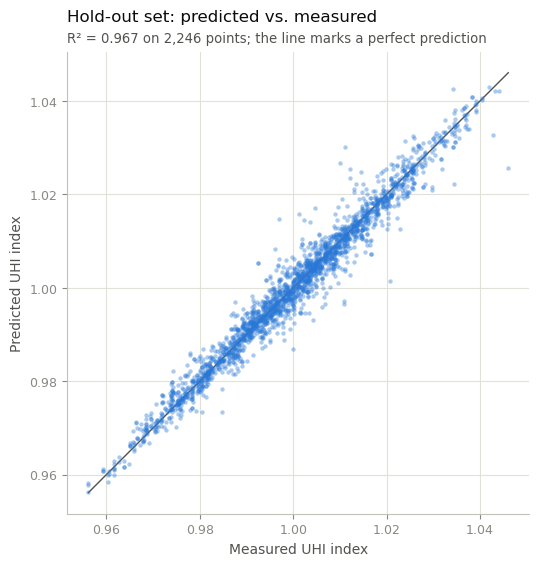

In [18]:
# Chart style: one accent colour for the data, recessive axes and grid
ACCENT, INK, INK_2, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

def style(ax, title, subtitle):
    ax.set_title(title, loc="left", color=INK, fontsize=12, pad=22)
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=INK_2, fontsize=9.5)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c3c2b7")

fig, ax = plt.subplots(figsize=(6, 6))
lo = min(trained.y_test.min(), trained.test_predictions.min())
hi = max(trained.y_test.max(), trained.test_predictions.max())
ax.plot([lo, hi], [lo, hi], color=INK_2, linewidth=1, zorder=1)
ax.scatter(trained.y_test, trained.test_predictions, s=10, color=ACCENT, alpha=0.4, linewidths=0, zorder=2)
ax.set_xlabel("Measured UHI index", color=INK_2)
ax.set_ylabel("Predicted UHI index", color=INK_2)
ax.set_aspect("equal")
style(ax, "Hold-out set: predicted vs. measured",
      f"R² = {trained.test_r2:.3f} on {len(trained.y_test):,} points; the line marks a perfect prediction")
plt.show()

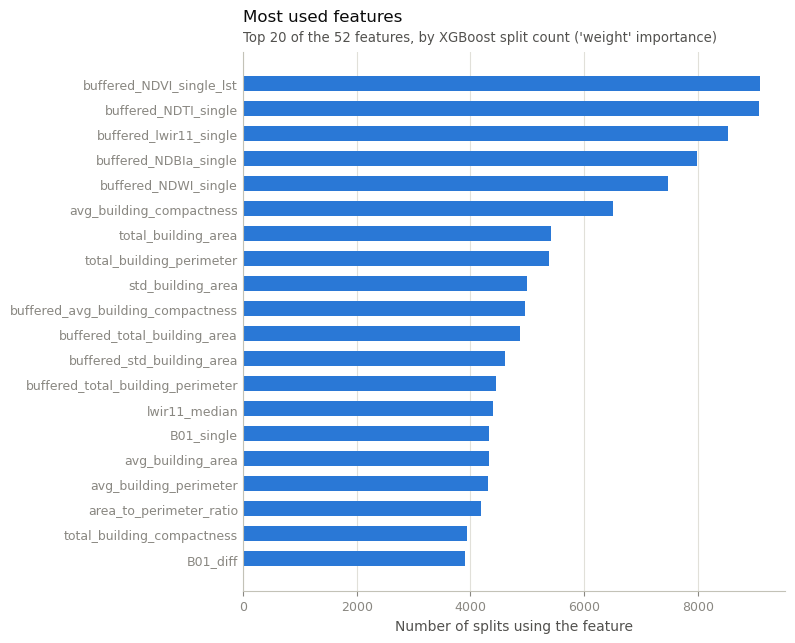

In [19]:
importance = modeling.feature_importance(trained).head(20).iloc[::-1]

fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(importance.index, importance.values, height=0.6, color=ACCENT)
ax.set_xlabel("Number of splits using the feature", color=INK_2)
ax.tick_params(axis="y", colors=INK_2, length=0)
style(ax, "Most used features", "Top 20 of the 52 features, by XGBoost split count ('weight' importance)")
ax.grid(axis="y", visible=False)
plt.show()

### Hyper-parameter search
The parameters come from the grid search below, which ran around the best result of earlier searches. It runs for many hours, so it is kept as a raw cell, and its logged results follow.

#### Log of the competition-time training runs

Outputs from the competition runs (bilinear Landsat / MODIS layers), kept for reference.

**Final model, as evaluated during the competition**

```text
5-fold cross-validation R² scores: [0.96699872 0.96579928 0.96545303 0.96466205 0.96668105]
Mean cross-validation R² score: 0.9659188252982448
Training R² score: 0.996541504026307
Test R² score: 0.9684476619397596
```

**Fine grid search above (5,832 candidates)**

```text
Fitting 5 folds for each of 5832 candidates, totalling 29160 fits
Best hyper-parameters (fine grid):  {'colsample_bytree': 0.7, 'gamma': 0, 'learning_rate': 0.04, 'max_depth': 15, 'min_child_weight': 7, 'n_estimators': 800, 'reg_alpha': 0.001, 'reg_lambda': 3.5, 'subsample': 0.6}
Best cross-validation R² score (fine grid):  0.9630911709744405
Test R² score:  0.9672501912902621
```

**Earlier search (5,000 candidates)**

```text
Fitting 5 folds for each of 5000 candidates, totalling 25000 fits
Best hyper-parameters:  {'subsample': 0.6, 'reg_lambda': 3, 'reg_alpha': 0.001, 'n_estimators': 700, 'min_child_weight': 7, 'max_depth': 15, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.7}
Best cross-validation R² score:  0.9626194972336275
Test R² score:  0.9669629945400869
```

**Earlier cross-validation run (settings noted as 100, 250, 100)**

```text
5-fold cross-validation R² scores: [0.96459473 0.96221595 0.96188603 0.96340389 0.96090557]
Mean cross-validation R² score: 0.9626012345941094
Training R² score: 0.996568622184949
Test R² score: 0.9668156018848765
```

**Top-10 parameter combinations of an earlier search**

```text
Top-10 parameter combinations (sorted by CV R², descending):
#1: {'colsample_bytree': 0.6, 'gamma': 0, 'learning_rate': 0.05, 'max_depth': 10, 'min_child_weight': 2, 'n_estimators': 500, 'subsample': 0.8} -> CV R²: 0.9594208496872735, test R²: 0.9686227844777204
#2: {'colsample_bytree': 0.6, 'gamma': 0, 'learning_rate': 0.05, 'max_depth': 10, 'min_child_weight': 3, 'n_estimators': 500, 'subsample': 0.6} -> CV R²: 0.959387304906965, test R²: 0.9684364566492588
#3: {'colsample_bytree': 0.6, 'gamma': 0, 'learning_rate': 0.05, 'max_depth': 10, 'min_child_weight': 1, 'n_estimators': 500, 'subsample': 0.6} -> CV R²: 0.9593570195997823, test R²: 0.9683813042406275
#4: {'colsample_bytree': 0.6, 'gamma': 0, 'learning_rate': 0.05, 'max_depth': 10, 'min_child_weight': 1, 'n_estimators': 500, 'subsample': 0.8} -> CV R²: 0.9593335093266772, test R²: 0.9677101506985757
#5: {'colsample_bytree': 0.8, 'gamma': 0, 'learning_rate': 0.05, 'max_depth': 10, 'min_child_weight': 3, 'n_estimators': 500, 'subsample': 0.6} -> CV R²: 0.9593013811566579, test R²: 0.9673107867674899
#6: {'colsample_bytree': 0.6, 'gamma': 0, 'learning_rate': 0.05, 'max_depth': 10, 'min_child_weight': 3, 'n_estimators': 500, 'subsample': 0.8} -> CV R²: 0.9591982507985435, test R²: 0.9692376644105315
#7: {'colsample_bytree': 0.6, 'gamma': 0, 'learning_rate': 0.05, 'max_depth': 10, 'min_child_weight': 4, 'n_estimators': 500, 'subsample': 0.8} -> CV R²: 0.9591951888723675, test R²: 0.9686349960711832
#8: {'colsample_bytree': 0.6, 'gamma': 0, 'learning_rate': 0.05, 'max_depth': 10, 'min_child_weight': 2, 'n_estimators': 500, 'subsample': 0.6} -> CV R²: 0.959093670386219, test R²: 0.967961224253537
#9: {'colsample_bytree': 0.8, 'gamma': 0, 'learning_rate': 0.05, 'max_depth': 10, 'min_child_weight': 1, 'n_estimators': 500, 'subsample': 0.6} -> CV R²: 0.9590861327823058, test R²: 0.9679732198463052
#10: {'colsample_bytree': 0.8, 'gamma': 0, 'learning_rate': 0.05, 'max_depth': 10, 'min_child_weight': 2, 'n_estimators': 500, 'subsample': 0.6} -> CV R²: 0.9590745805965165, test R²: 0.9682774007783963
```

## 11. Predict the submission points

In [20]:
submission_table = pd.DataFrame(test_mapped.drop(columns="geometry"))
predictions = modeling.predict(trained, submission_table)

submission = pd.DataFrame({"Longitude": test_df["Longitude"].values, "Latitude": test_df["Latitude"].values,
                           config.TARGET: predictions})
config.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
submission.to_csv(config.OUTPUT_DIR / "submission_4.3.csv", index=False)
submission.describe()

,Longitude,Latitude,UHI Index
count,1040.000000,1040.000000,1040.000000
mean,-73.934816,40.807991,0.999931
std,0.028661,0.023200,0.015943
min,-73.993163,40.758877,0.957092
25%,-73.957030,40.790802,0.988911
50%,-73.934618,40.809553,0.999813
75%,-73.910655,40.823054,1.011074
max,-73.879537,40.859243,1.043300
